# Harmonize Abundance Data Between Cohorts

Check if abundance values are comparable across datasets (focusing on genus level only)

1) take only the overlapping 93 genus features
2) combine the two datasets
3) apply a CLR transformation to the samples
4) use pyComBat (industry standard algorithm for controlling batch effects in gut microbiome data)
5) perform a PCA to see if we fix the batch effect of the processed datasets

In [13]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from skbio.stats.composition import clr
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from inmoose.pycombat import pycombat_norm

Read in data:

In [27]:
# read in merged data frames
zhou_merged = pd.read_csv('data/preprocessed/merged_dfs/zhou_genus_merged_df.csv')
levi_merged = pd.read_csv('data/preprocessed/merged_dfs/levi_genus_merged_df.csv')

In [15]:
# separate out into abundance vs. metadata
# Zhou
Zmeta_end_idx = zhou_merged.columns.get_loc('Cohort') # last metadata column in merged df
zhou_abundances = zhou_merged.iloc[:, Zmeta_end_idx + 1:]
zhou_meta = zhou_merged.iloc[:, :Zmeta_end_idx + 1]

# Levi
Lmeta_end_idx = levi_merged.columns.get_loc('Previous treatments') # last metadata column in merged df
levi_abundances = levi_merged.iloc[:, Lmeta_end_idx + 1:]
levi_meta = levi_merged.iloc[:, :Lmeta_end_idx + 1]
levi_meta.head()

,Registrant_number,sample_date,FD,Have serum gene sample,Recorded nutritional for at least 3 days,type,age,gender,BMI,diagnosis_date,...,treatment_start,treatment_end,treatment_duration,Registrant connected,Connection type,MS_type short,One_Relapse_or_more_during_following_year,worse_EDSS_after_one_year,worse_EDSS_after_one_year.1,Previous treatments
0,32313,2018-08-08,FD2917,No,Yes,MS,50.40,female,29,2004-03-16,...,2005-04-01,NaN,4877.0,none,none,RRMS,0,0,No info,Interferon beta 1a 44 - 01/04/2005 -
1,911500,2017-06-07,FD2387,No,No,MS,53.41,female,21,2003-12-18,...,2005-11-22,NaN,4215.0,none,none,RRMS,0,0,No info,Interferon-beta-1-b - 22/11/2005 -
2,976854,2018-07-16,FD2901,No,No,MS,57.15,male,24,1987-01-01,...,2010-01-01,NaN,3118.0,none,none,RRMS,0,0,1,Interferon-beta-1-a - 01/01/2010 -
3,235772,2018-05-15,FD2878,No,No,MS,42.86,female,20,1998-11-01,...,2011-06-19,NaN,2522.0,none,none,RRMS,0,0,0,COPOLYMER -1 - 06/04/2010 - 01/01/2011;Immunog...
4,633807,2016-02-18,FD2298,Yes,Yes,MS,44.90,female,24,2011-02-01,...,2012-03-18,2018-06-07,2272.0,none,none,CIS,0,0,No info,Immunoglobulin IgG - 18/03/2012 - 07/06/2018


In [16]:
# see the total overlapping features between the cohorts
overlapping_genus = set(zhou_abundances.columns).intersection(set(levi_abundances.columns))
print(f"Number of overlapping genus features between the two datasets: {len(overlapping_genus)}")

Number of overlapping genus features between the two datasets: 93


### Combine the two datasets based on their overlapping features

In [17]:
## get all sample IDs
# Zhou
zhou_sampleids = zhou_meta['iMSMS_ID']

# Levi
levi_sampleids = levi_meta['FD']

# combine the two dataframes to get all sample IDs
sampleids = pd.concat([zhou_sampleids, levi_sampleids])

In [18]:
# make copy of dataframes that only have overlap, and label each df to be in a certain cohort
genus_matches = list(overlapping_genus)
zhou_overlap = zhou_abundances[genus_matches].copy()
levi_overlap = levi_abundances[genus_matches].copy()

zhou_overlap['Cohort'] = 'Zhou'
levi_overlap['Cohort'] = 'Levi'

# concat the two dataframes
combined_df = pd.concat([zhou_overlap, levi_overlap])
combined_df.index = sampleids
print(f"Number of samples in combined df: {combined_df.shape[0]}")
print(f"Number of features in combined df: {combined_df.shape[1] - 1}\n") # one column is the Cohort
print(combined_df['Cohort'].value_counts())
combined_df.head()

Number of samples in combined df: 1339
Number of features in combined df: 93

Cohort
Zhou    1152
Levi     187
Name: count, dtype: int64


,enterococcus,staphylococcus,faecalibacterium,megamonas,butyricicoccus,ruminiclostridium,allisonella,butyricimonas,mobiluncus,bacteroides,...,catenibacterium,sutterella,paraprevotella,acetobacter,desulfovibrio,intestinimonas,bilophila,peptostreptococcus,azospirillum,Cohort
71401-0001,0.000113,0.005638,0.027773,0.000000,0.001554,0.003214,0.000000,0.002636,0.000078,0.392568,...,0.000007,0.005209,0.015825,0.000033,0.000054,0.003070,3.702947e-04,0.000034,9.760651e-06,Zhou
71401-0009,0.000055,0.000036,0.009559,0.000000,0.001190,0.006008,0.000005,0.010574,0.000020,0.568847,...,0.000009,0.000007,0.000249,0.000000,0.000000,0.000796,9.274756e-07,0.000432,7.045568e-03,Zhou
71401-0017,0.000087,0.000006,0.021332,0.000001,0.002046,0.001166,0.000000,0.000684,0.000025,0.431964,...,0.000022,0.000005,0.009516,0.000000,0.000005,0.000395,3.113305e-03,0.000050,5.273213e-07,Zhou
71401-0022,0.000084,0.000005,0.016075,0.000000,0.000403,0.002999,0.000000,0.003426,0.000004,0.390547,...,0.000007,0.000005,0.000272,0.000002,0.000002,0.000451,3.583764e-06,0.000010,8.959409e-07,Zhou
71401-0027,0.000043,0.000023,0.016518,0.000000,0.000967,0.011344,0.000004,0.003817,0.000033,0.594145,...,0.000000,0.000003,0.000365,0.000001,0.000000,0.002783,5.533330e-06,0.000052,3.319998e-06,Zhou


### Apply CLR transformation Across Samples

In [19]:
og_abundances = combined_df.drop(columns=['Cohort'])

# get the fraction of non-zero abundances for each column
nonzero_freqs = (og_abundances > 0).mean(axis=0)

# only keep microbes in at least 15% of the patients
filt_abundances = og_abundances.loc[:, nonzero_freqs >= 0.15]
print(f"{len(microbes_to_keep)} microbes kept after dropping those not present in at least 15% of subjects")

# need to add a pseudocount to deal with zeros
pseudo_count = 1e-6
pseudo_abundances = filt_abundances + pseudo_count

# apply the CLR transformation
clr_abundances = clr(pseudo_abundances)
clr_df = pd.DataFrame(clr_abundances, columns=filt_abundances.columns, index=filt_abundances.index)
clr_df.head()

91 microbes kept after dropping those not present in at least 15% of subjects


,enterococcus,staphylococcus,faecalibacterium,megamonas,butyricicoccus,ruminiclostridium,allisonella,butyricimonas,mobiluncus,bacteroides,...,hungatella,catenibacterium,sutterella,paraprevotella,acetobacter,desulfovibrio,intestinimonas,bilophila,peptostreptococcus,azospirillum
71401-0001,-0.846628,3.050542,4.644948,-5.586920,1.762558,2.488568,-5.586920,2.290472,-1.216394,7.293549,...,1.214341,-3.468199,2.971325,4.082494,-2.062261,-1.574262,2.442749,0.330076,-2.026946,-3.211024
71401-0009,-1.449184,-1.866552,3.695853,-5.469542,1.612966,3.231426,-3.661070,3.796720,-2.427846,7.781827,...,1.197552,-3.186036,-3.338955,0.053881,-5.469542,-5.469542,1.211029,-4.813331,0.600595,3.390754
71401-0017,-0.734445,-3.220190,4.756149,-4.491771,2.412261,1.850691,-5.211873,1.318222,-1.941870,7.764226,...,1.395901,-2.093031,-3.463388,3.948966,-5.211873,-3.375584,0.770780,2.831888,-1.288550,-4.788358
71401-0022,-0.114095,-2.706827,5.125768,-4.559313,1.442531,3.446960,-4.559313,3.580151,-2.858261,8.315993,...,1.529521,-2.459146,-2.706827,1.051499,-3.532597,-3.532597,1.553613,-3.036792,-2.174654,-3.919597
71401-0027,-1.534171,-2.133986,4.390283,-5.321989,1.553476,4.014581,-3.630665,2.925464,-1.789764,7.972890,...,1.739619,-5.321989,-3.858735,0.581190,-4.576883,-5.321989,2.609750,-3.445073,-1.351447,-3.858735


### PCA Prior to Performing Batch Correction

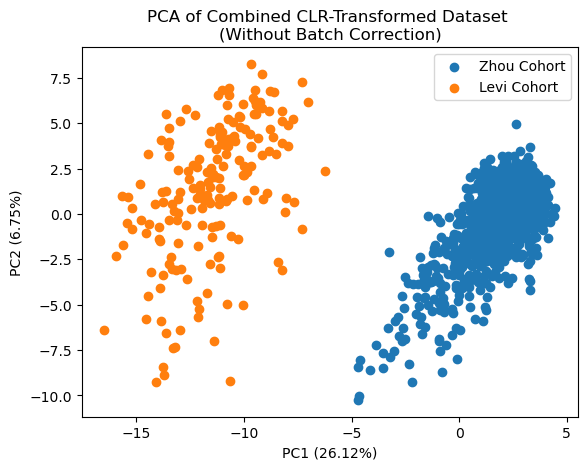

In [20]:
# scale data
scaler = StandardScaler()
clrS = scaler.fit_transform(clr_df)

# perform PCA
ncomp = 2
pca = PCA(ncomp)
pca_trans = pca.fit_transform(clrS)

# plot PC1 and PC2
zhou_idx = combined_df['Cohort'] == 'Zhou'
levi_idx = combined_df['Cohort'] == 'Levi'

plt.scatter(pca_trans[zhou_idx,0], pca_trans[zhou_idx,1], label='Zhou Cohort')
plt.scatter(pca_trans[levi_idx,0], pca_trans[levi_idx,1], label='Levi Cohort')
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0] * 100:.2f}%)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1] * 100:.2f}%)")
plt.title('PCA of Combined CLR-Transformed Dataset \n(Without Batch Correction)')
plt.legend()
plt.show()

### Use PyComBat for Batch Correction

Also include disease status and other metadata as covariates.

In [22]:
## encode the covariates we should account for in the batch correction - combine metadata across both cohorts

## Zhou
zhou_meta_covar = zhou_meta.loc[:,['bmi', 'age', 'sex', 'disease']]
zhou_meta_covar.index = zhou_meta['iMSMS_ID']

# encode gender and disease status
zhou_meta_covar['sex'] = zhou_meta_covar['sex'].replace('M', 0)
zhou_meta_covar['sex'] = zhou_meta_covar['sex'].replace('F', 1)
zhou_meta_covar['disease'] = zhou_meta_covar['disease'].replace('MS', 0)
zhou_meta_covar['disease'] = zhou_meta_covar['disease'].replace('Control', 1)


## Levi
levi_meta_covar = levi_meta.loc[:,['BMI', 'age', 'gender', 'type']]
levi_meta_covar.index = levi_meta['FD']

# rename the column names to match the Zhou metadata's column names
levi_meta_covar = levi_meta_covar.rename(columns={'BMI': 'bmi', 'gender': 'sex', 'type': 'disease'})

# encode gender and disease status
levi_meta_covar['sex'] = levi_meta_covar['sex'].replace('male', 0)
levi_meta_covar['sex'] = levi_meta_covar['sex'].replace('female', 1)
levi_meta_covar['disease'] = levi_meta_covar['disease'].replace('MS', 0)
levi_meta_covar['disease'] = levi_meta_covar['disease'].replace('Control', 1)

# combine the two dataframes to get final covariate df
covariates = pd.concat([zhou_meta_covar, levi_meta_covar])
covariates.head()

,bmi,age,sex,disease
71401-0001,25.672988,54.0,0,0
71401-0009,26.255155,35.0,1,0
71401-0017,21.875320,38.0,1,0
71401-0022,21.675052,69.0,0,0
71401-0027,21.663146,45.0,1,0


In [23]:
# run the batch correction with PyComBat
cohorts = combined_df['Cohort']
normalized_df = pycombat_norm(clr_df.T, batch=cohorts, covariates=covariates).transpose()
normalized_df.head()

,enterococcus,staphylococcus,faecalibacterium,megamonas,butyricicoccus,ruminiclostridium,allisonella,butyricimonas,mobiluncus,bacteroides,...,hungatella,catenibacterium,sutterella,paraprevotella,acetobacter,desulfovibrio,intestinimonas,bilophila,peptostreptococcus,azospirillum
71401-0001,-0.979171,2.961759,4.936173,-5.105300,1.872930,2.186824,-5.243254,2.135965,0.606776,6.755330,...,0.849996,-3.350939,2.748383,4.011225,-1.683646,-1.531508,2.299877,0.078778,-2.066296,-2.873983
71401-0009,-1.620822,-1.893274,3.583825,-4.973606,1.614736,3.019979,-3.232013,3.861020,-2.050730,7.654843,...,0.830475,-3.062746,-3.340556,-0.379375,-5.294092,-5.288693,0.737329,-5.178486,1.782552,3.758455
71401-0017,-0.859709,-3.229827,5.094622,-3.876585,2.994309,1.471411,-4.851578,1.022479,-0.984667,7.622418,...,1.061106,-1.946380,-3.460624,3.865699,-5.021059,-3.268970,0.178833,2.635970,-0.984687,-4.458642
71401-0022,-0.199107,-2.722944,5.621286,-3.952364,1.320568,3.261712,-4.170083,3.612990,-2.994912,8.638893,...,1.216474,-2.320320,-2.730601,0.707883,-3.241653,-3.420416,1.171928,-3.362621,-2.282662,-3.585847
71401-0027,-1.711324,-2.157332,4.573306,-4.808058,1.512057,3.898329,-3.200260,2.863199,-0.651000,8.006823,...,1.460767,-5.244351,-3.842103,0.195314,-4.348207,-5.146372,2.511733,-3.779940,-1.076819,-3.524702


### Perform PCA with Transformed Data to Study Batch Effect

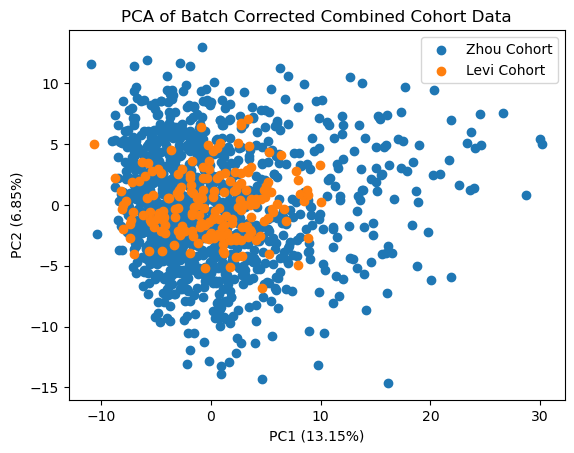

In [24]:
# perform PCA
ncomp = 2
pca = PCA(ncomp)
pca_trans = pca.fit_transform(normalized_df)

# plot PC1 and PC2
zhou_idx = combined_df['Cohort'] == 'Zhou'
levi_idx = combined_df['Cohort'] == 'Levi'

plt.scatter(pca_trans[zhou_idx,0], pca_trans[zhou_idx,1], label='Zhou Cohort')
plt.scatter(pca_trans[levi_idx,0], pca_trans[levi_idx,1], label='Levi Cohort')
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0] * 100:.2f}%)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1] * 100:.2f}%)")
plt.title('PCA of Batch Corrected Combined Cohort Data')
plt.legend()
plt.show()

We have now removed the batch effect while accounting for covariates (age, sex, BMI, disease status)!

### Save Batch-Corrected Datasets to File

In [25]:
# separate Zhou and Levi dataframes to save separately
normalized_df.index = covariates.index
normalized_df['Cohort'] = combined_df['Cohort']

# make separate Zhou/Levi dataframes
zhou_idx = normalized_df['Cohort'] == 'Zhou'
levi_idx = normalized_df['Cohort'] == 'Levi'

zhou_normalized_data = normalized_df.loc[zhou_idx, :].drop(columns='Cohort')
levi_normalized_data = normalized_df.loc[levi_idx, :].drop(columns='Cohort')

# add the index back as a column name
zhou_normalized_data = zhou_normalized_data.reset_index(names='iMSMS_ID')
levi_normalized_data = levi_normalized_data.reset_index(names='FD')
levi_normalized_data.head()

,FD,enterococcus,staphylococcus,faecalibacterium,megamonas,butyricicoccus,ruminiclostridium,allisonella,butyricimonas,mobiluncus,...,hungatella,catenibacterium,sutterella,paraprevotella,acetobacter,desulfovibrio,intestinimonas,bilophila,peptostreptococcus,azospirillum
0,FD2917,-1.693280,4.196175,3.401674,-5.666456,-0.215993,0.251486,-4.969664,-0.242311,-0.461449,...,0.036277,-3.435645,-2.534746,3.281912,3.601017,-3.427693,0.320089,4.510397,-2.611510,-4.729063
1,FD2387,-1.714575,5.200276,4.882615,-5.685146,2.562419,0.232782,-4.992359,-0.260262,-0.384542,...,0.018802,-3.460429,-2.571023,-0.284907,2.391032,-3.464121,0.304592,5.540239,-2.625205,3.017882
2,FD2901,-1.582519,-2.429709,4.056410,1.277152,2.365534,0.348769,0.772880,4.790935,-0.743430,...,0.127167,2.669015,-2.346061,4.012261,2.176768,-3.238223,0.400689,-0.883090,-2.540282,2.834228
3,FD2878,-1.001481,-1.615535,1.380666,-5.059303,0.192882,0.859104,-4.232425,0.340833,-0.433760,...,0.603962,-2.630517,-1.356250,0.384071,-3.561169,6.042509,0.823510,-0.209092,1.514496,-3.856452
4,FD2298,-0.946439,-1.538409,1.416742,-5.010996,0.225413,0.907448,-4.173768,0.387229,1.284900,...,0.649129,-2.566459,-1.262486,0.435707,-3.505285,-2.150137,0.863564,-0.145244,-2.131235,-3.787024


In [26]:
# save to file
zhou_normalized_data.to_csv('data/preprocessed/batch_corrected/normalized_zhou_genus.csv', index=False)
levi_normalized_data.to_csv('data/preprocessed/batch_corrected/normalized_levi_genus.csv', index=False)